# Setup

In [1]:
from pathlib import Path
from torch_geometric.datasets import MoleculeNet

DATA_ROOT = Path("data/MoleculeNet")

dataset = MoleculeNet(
    root=str(DATA_ROOT),
    name="BBBP"
)

print(dataset)
print("Number of molecules:", len(dataset))
print("First graph:", dataset[0])

BBBP(2039)
Number of molecules: 2039
First graph: Data(x=[20, 9], edge_index=[2, 40], edge_attr=[40, 3], smiles='[Cl].CC(C)NCC(O)COc1cccc2ccccc12', y=[1, 1])


In [2]:
graph = dataset[0]
print("Node-feature shape:", graph.x.shape)
print("Edge-index shape:", graph.edge_index.shape)
print("Edge-feature shape:", graph.edge_attr.shape)
print("Label:", graph.y)
print("SMILES:", graph.smiles)

Node-feature shape: torch.Size([20, 9])
Edge-index shape: torch.Size([2, 40])
Edge-feature shape: torch.Size([40, 3])
Label: tensor([[1.]])
SMILES: [Cl].CC(C)NCC(O)COc1cccc2ccccc12


## Imports and global settings

All randomness in this notebook is controlled by one fixed seed (`SEED = 42`).

In [3]:
import random
import textwrap
import warnings
from collections import Counter

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import networkx as nx

from rdkit import Chem, RDLogger
from rdkit.Chem import Draw
from torch_geometric.loader import DataLoader
from torch_geometric.utils.smiles import x_map, e_map

RDLogger.DisableLog("rdApp.*")          # silence RDKit parse warnings; invalid SMILES are counted explicitly below
warnings.filterwarnings("ignore", category=UserWarning)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 200)
print("torch", torch.__version__)

torch 2.11.0+cu128


# Part A — Define the task and inspect the dataset

## A.1 Task definition

| Item | Description |
|---|---|
| **Input** | One small molecule, given as a SMILES string and converted to a molecular graph (atoms = nodes, chemical bonds = edges, with categorical atom and bond features). |
| **Output** | One probability $P(\text{p\_np}=1 \mid \text{molecule})$ for the whole molecule, turned into a binary decision with a threshold chosen on validation data. |
| **Unit of analysis** | The **molecule** (one graph = one sample = one label). Predictions are graph-level, not per atom. After cleaning, each unique canonical molecule appears exactly once. |
| **Intended technical use** | An educational benchmark for comparing molecular representations (Morgan fingerprints vs. a bond-aware GNN) and evaluation protocols (random vs. scaffold split). At most it could act as an early *in-silico* screening filter for ranking candidates; it is **not** a drug-development or clinical decision tool. |

**Labels (`p_np`)**

* **Positive (1)**: the compound is labelled as *penetrating* the blood–brain barrier (BBB+), i.e. it was reported to reach the central nervous system in meaningful amounts.
* **Negative (0)**: the compound is labelled as *non-penetrating* (BBB−).

These are curated literature labels (Martins et al., 2012) that come from different experimental sources and cut-offs. They are a binarised research annotation, not a clinical measurement for a patient, and say nothing about safety or efficacy.

## A.2 Dataset size, label quality, invalid graphs, class balance

The PyG loader parses each SMILES in the raw CSV with RDKit and **silently skips** molecules that cannot be parsed (the
"Skipping molecule ... zero atoms" warnings above). To report every record I therefore also read the cached raw CSV
(`data/MoleculeNet/bbbp/raw/BBBP.csv`, which PyG downloaded; no separate file is needed) and parse every SMILES myself.

In [4]:
raw_df = pd.read_csv(DATA_ROOT / "bbbp" / "raw" / "BBBP.csv")
raw_df["rdkit_valid"] = [Chem.MolFromSmiles(s) is not None for s in raw_df["smiles"]]

print(f"Raw CSV records                         : {len(raw_df)}")
print(f"Missing SMILES / labels in raw CSV      : {raw_df['smiles'].isna().sum()} / {raw_df['p_np'].isna().sum()}")
print(f"SMILES that RDKit cannot parse (invalid): {(~raw_df['rdkit_valid']).sum()}")
print(f"Graphs kept by the PyG loader           : {len(dataset)}")

invalid_df = raw_df.loc[~raw_df["rdkit_valid"], ["num", "name", "p_np", "smiles"]]
invalid_df

Raw CSV records                         : 2050
Missing SMILES / labels in raw CSV      : 0 / 0
SMILES that RDKit cannot parse (invalid): 11
Graphs kept by the PyG loader           : 2039


,num,name,p_np,smiles
59,60,15,1,O=N([O-])C1=C(CN=C1NCCSCc2ncccc2)Cc3ccccc3
61,62,22767,1,c1(nc(NC(N)=[NH2])sc1)CSCCNC(=[NH]C#N)NC
391,393,ICI17148,1,Cc1nc(sc1)\[NH]=C(\N)N
614,616,5-6,1,s1cc(CSCCN\C(NC)=[NH]\C#N)nc1\[NH]=C(\N)N
642,644,12,0,c1c(c(ncc1)CSCCN\C(=[NH]\C#N)NCC)Br
645,647,16,1,n1c(csc1\[NH]=C(\N)N)c1ccccc1
646,648,17,0,n1c(csc1\[NH]=C(\N)N)c1cccc(c1)N
647,649,18,0,n1c(csc1\[NH]=C(\N)N)c1cccc(c1)NC(C)=O
648,650,19,0,n1c(csc1\[NH]=C(\N)N)c1cccc(c1)N\C(NC)=[NH]\C#N
649,651,2,1,s1cc(nc1\[NH]=C(\N)N)C


In [5]:
# One row per PyG graph (the PyG dataset keeps CSV order, skipping the invalid rows)
records = []
for i, g in enumerate(dataset):
    y = g.y.view(-1)
    records.append({
        "idx": i,
        "smiles": g.smiles,
        "y": float(y[0]) if y.numel() == 1 else np.nan,
        "n_atoms": int(g.num_nodes),
        "n_bonds": int(g.edge_index.size(1) // 2),   # each chemical bond is stored as two directed edges
    })
mol_df = pd.DataFrame(records)

# Sanity: the PyG graphs are exactly the RDKit-valid raw rows, in the same order
assert mol_df["smiles"].tolist() == raw_df.loc[raw_df["rdkit_valid"], "smiles"].tolist()
mol_df["name"] = raw_df.loc[raw_df["rdkit_valid"], "name"].values

n_nonfinite = (~np.isfinite(mol_df["y"])).sum()
n_empty     = (mol_df["n_atoms"] == 0).sum()
n_no_edges  = (mol_df["n_bonds"] == 0).sum()

# Canonicalize every valid SMILES with RDKit (stereochemistry is kept)
mol_df["canonical"] = [Chem.MolToSmiles(Chem.MolFromSmiles(s)) for s in mol_df["smiles"]]
n_bad_canon = mol_df["canonical"].isin(["", None]).sum()

print(f"Graphs in PyG dataset              : {len(mol_df)}")
print(f"Missing / non-finite labels        : {n_nonfinite}")
print(f"Empty graphs (0 atoms)             : {n_empty}")
print(f"Graphs with atoms but no bonds     : {n_no_edges}   (isolated counter-ion nodes such as [Cl] can still occur inside a graph)")
print(f"Failed canonicalizations           : {n_bad_canon}")
print(f"Records with multiple fragments '.': {mol_df['smiles'].str.contains('.', regex=False).sum()}  (salts / counter-ions, kept as one record)")

def class_table(y):
    c = pd.Series(y).astype(int).value_counts().sort_index()
    return pd.DataFrame({"count": c, "proportion": (c / c.sum()).round(4)}).rename(index={0: "0 (BBB-)", 1: "1 (BBB+)"})

print("\nClass balance (raw CSV, all 2050 rows):")
display(class_table(raw_df["p_np"]))
print("Class balance (PyG graphs, before de-duplication):")
display(class_table(mol_df["y"]))

Graphs in PyG dataset              : 2039
Missing / non-finite labels        : 0
Empty graphs (0 atoms)             : 0
Graphs with atoms but no bonds     : 0   (isolated counter-ion nodes such as [Cl] can still occur inside a graph)
Failed canonicalizations           : 0
Records with multiple fragments '.': 105  (salts / counter-ions, kept as one record)

Class balance (raw CSV, all 2050 rows):


,count,proportion
p_np,,
0 (BBB-),483,0.2356
1 (BBB+),1567,0.7644


Class balance (PyG graphs, before de-duplication):


,count,proportion
y,,
0 (BBB-),479,0.2349
1 (BBB+),1560,0.7651


### Duplicate molecules

Duplicates are detected on the **RDKit canonical SMILES**, so the same molecule written in two different ways
(e.g. `CC(=O)Oc1ccccc1C(O)=O` and `C1=CC=CC(=C1C(O)=O)OC(C)=O`, both aspirin) is caught even when the raw strings differ.

In [6]:
grp = mol_df.groupby("canonical")["y"].agg(n_records="size", n_labels="nunique")
dup_groups      = grp[grp["n_records"] > 1]
conflict_groups = grp[grp["n_labels"] > 1]
consistent_dups = dup_groups[dup_groups["n_labels"] == 1]

exact_raw_dups = mol_df["smiles"].duplicated(keep=False).sum()
print(f"Unique canonical molecules                       : {len(grp)}")
print(f"Canonical molecules occurring more than once     : {len(dup_groups)}  ({dup_groups['n_records'].sum()} records)")
print(f"   ...of which raw SMILES strings are identical  : {exact_raw_dups} records -> all duplicates use different SMILES strings")
print(f"   ...with consistent labels                     : {len(consistent_dups)} groups ({consistent_dups['n_records'].sum()} records)")
print(f"   ...with CONFLICTING labels                    : {len(conflict_groups)} groups ({conflict_groups['n_records'].sum()} records)")
print(f"Group size distribution                          : {dict(Counter(dup_groups['n_records']))}")

print("\nExamples of consistent duplicates (different raw SMILES, same canonical molecule):")
display(mol_df[mol_df["canonical"].isin(consistent_dups.index[:3])]
        .sort_values("canonical")[["idx", "name", "y", "smiles", "canonical"]])

Unique canonical molecules                       : 1975
Canonical molecules occurring more than once     : 60  (124 records)
   ...of which raw SMILES strings are identical  : 0 records -> all duplicates use different SMILES strings
   ...with consistent labels                     : 50 groups (104 records)
   ...with CONFLICTING labels                    : 10 groups (20 records)
Group size distribution                          : {2: 56, 3: 4}

Examples of consistent duplicates (different raw SMILES, same canonical molecule):


,idx,name,y,smiles,canonical
432,432,Divinylether,1.0,C=COC=C,C=COC=C
1647,1647,vinyl-ether,1.0,C(=C)OC=C,C=COC=C
3,3,24,1.0,C1CCN(CC1)Cc1cccc(c1)OCCCNC(=O)C,CC(=O)NCCCOc1cccc(CN2CCCCC2)c1
655,655,24,1.0,C1CN(CCC1)Cc1cccc(c1)OCCCNC(=O)C,CC(=O)NCCCOc1cccc(CN2CCCCC2)c1
97,97,acetaminophen,1.0,CC(=O)Nc1ccc(O)cc1,CC(=O)Nc1ccc(O)cc1
1932,1932,paracetamol(acetaminophen),1.0,N(C(=O)C)C1=CC=C(O)C=C1,CC(=O)Nc1ccc(O)cc1


In [7]:
print("Records in conflicting-label groups (all will be removed):")
conflict_df = (mol_df[mol_df["canonical"].isin(conflict_groups.index)]
               .sort_values(["canonical", "y"])[["idx", "name", "y", "smiles", "canonical"]])
conflict_df

Records in conflicting-label groups (all will be removed):


,idx,name,y,smiles,canonical
98,98,acetylsalicylate,0.0,CC(=O)Oc1ccccc1C(O)=O,CC(=O)Oc1ccccc1C(=O)O
996,996,aspirin,1.0,C1=CC=CC(=C1C(O)=O)OC(C)=O,CC(=O)Oc1ccccc1C(=O)O
566,566,loratadine,0.0,CCOC(=O)N1CCC(CC1)=C2c3ccc(Cl)cc3CCc4cccnc24,CCOC(=O)N1CCC(=C2c3ccc(Cl)cc3CCc3cccnc32)CC1
1323,1323,loratadine,1.0,C1=CC(=CC2=C1C(C3=C(CC2)C=CC=N3)=C4CCN(C(OCC)=O)CC4)Cl,CCOC(=O)N1CCC(=C2c3ccc(Cl)cc3CCc3cccnc32)CC1
547,547,loperamide,0.0,CN(C)C(=O)C(CCN1CCC(O)(CC1)c2ccc(Cl)cc2)(c3ccccc3)c4ccccc4,CN(C)C(=O)C(CCN1CCC(O)(c2ccc(Cl)cc2)CC1)(c1ccccc1)c1ccccc1
16,16,BRL53080,1.0,CN(C)C(=O)C(CCN1CCC(O)(CC1)c1ccc(Cl)cc1)(c1ccccc1)c1ccccc1,CN(C)C(=O)C(CCN1CCC(O)(c2ccc(Cl)cc2)CC1)(c1ccccc1)c1ccccc1
124,124,atropine,0.0,CN1C2CCC1CC(C2)OC(=O)C(CO)c3ccccc3,CN1C2CCC1CC(OC(=O)C(CO)c1ccccc1)C2
1686,1686,atropine(hyoscyamine),1.0,C1=CC=CC=C1C(C(OC2CC3N(C)C(C2)CC3)=O)CO,CN1C2CCC1CC(OC(=O)C(CO)c1ccccc1)C2
172,172,Trimetrexate,0.0,COc1cc(NCc2ccc3nc(N)nc(N)c3c2C)cc(OC)c1OC,COc1cc(NCc2ccc3nc(N)nc(N)c3c2C)cc(OC)c1OC
1630,1630,trimetrexate,1.0,C1=C3C(=C(C(=C1)CNC2=CC(=C(C(=C2)OC)OC)OC)C)C(=NC(=N3)N)N,COc1cc(NCc2ccc3nc(N)nc(N)c3c2C)cc(OC)c1OC


### Cleaning rule (applied once, before any split)

1. Remove invalid SMILES / empty graphs (11 raw rows that RDKit cannot parse; PyG already dropped them, and there are no empty graphs left).
2. Remove **all** records of a canonical molecule whose duplicate records have **conflicting** labels.
3. For duplicate groups with **consistent** labels, keep the **first** record (lowest index) and drop the rest.

Both split strategies in Part C are built from the resulting `clean_df` / `clean_graphs`.

In [8]:
n_raw = len(raw_df)
step1 = mol_df[(mol_df["n_atoms"] > 0) & np.isfinite(mol_df["y"])]
step2 = step1[~step1["canonical"].isin(conflict_groups.index)]
step3 = step2.drop_duplicates(subset="canonical", keep="first")
clean_df = step3.reset_index(drop=True)

cleaning_log = pd.DataFrame([
    ("Raw CSV records",                                       n_raw,                    ""),
    ("Removed: invalid SMILES (RDKit parse failure)",        n_raw - len(mol_df),       "dropped by PyG loader"),
    ("Removed: empty graph / non-finite label",              len(mol_df) - len(step1),  ""),
    ("Removed: records in conflicting-label groups",         len(step1) - len(step2),   f"{len(conflict_groups)} molecules"),
    ("Removed: redundant copies of consistent duplicates",   len(step2) - len(step3),   f"{len(consistent_dups)} molecules kept once"),
    ("Clean molecules used for all splits",                  len(clean_df),             ""),
], columns=["step", "records", "note"])
display(cleaning_log)

assert clean_df["canonical"].is_unique
print("Class balance after cleaning:")
display(class_table(clean_df["y"]))

,step,records,note
0,Raw CSV records,2050,
1,Removed: invalid SMILES (RDKit parse failure),11,dropped by PyG loader
2,Removed: empty graph / non-finite label,0,
3,Removed: records in conflicting-label groups,20,10 molecules
4,Removed: redundant copies of consistent duplicates,54,50 molecules kept once
5,Clean molecules used for all splits,1965,


Class balance after cleaning:


,count,proportion
y,,
0 (BBB-),465,0.2366
1 (BBB+),1500,0.7634


The dataset is **imbalanced**: roughly three quarters of the molecules are BBB+. Accuracy alone is therefore
misleading (predicting "1" for everything gives ~76 % accuracy), so later parts report ROC-AUC, PR-AUC, sensitivity,
specificity and F1 as well.

## A.3 Example molecular structures (both classes)

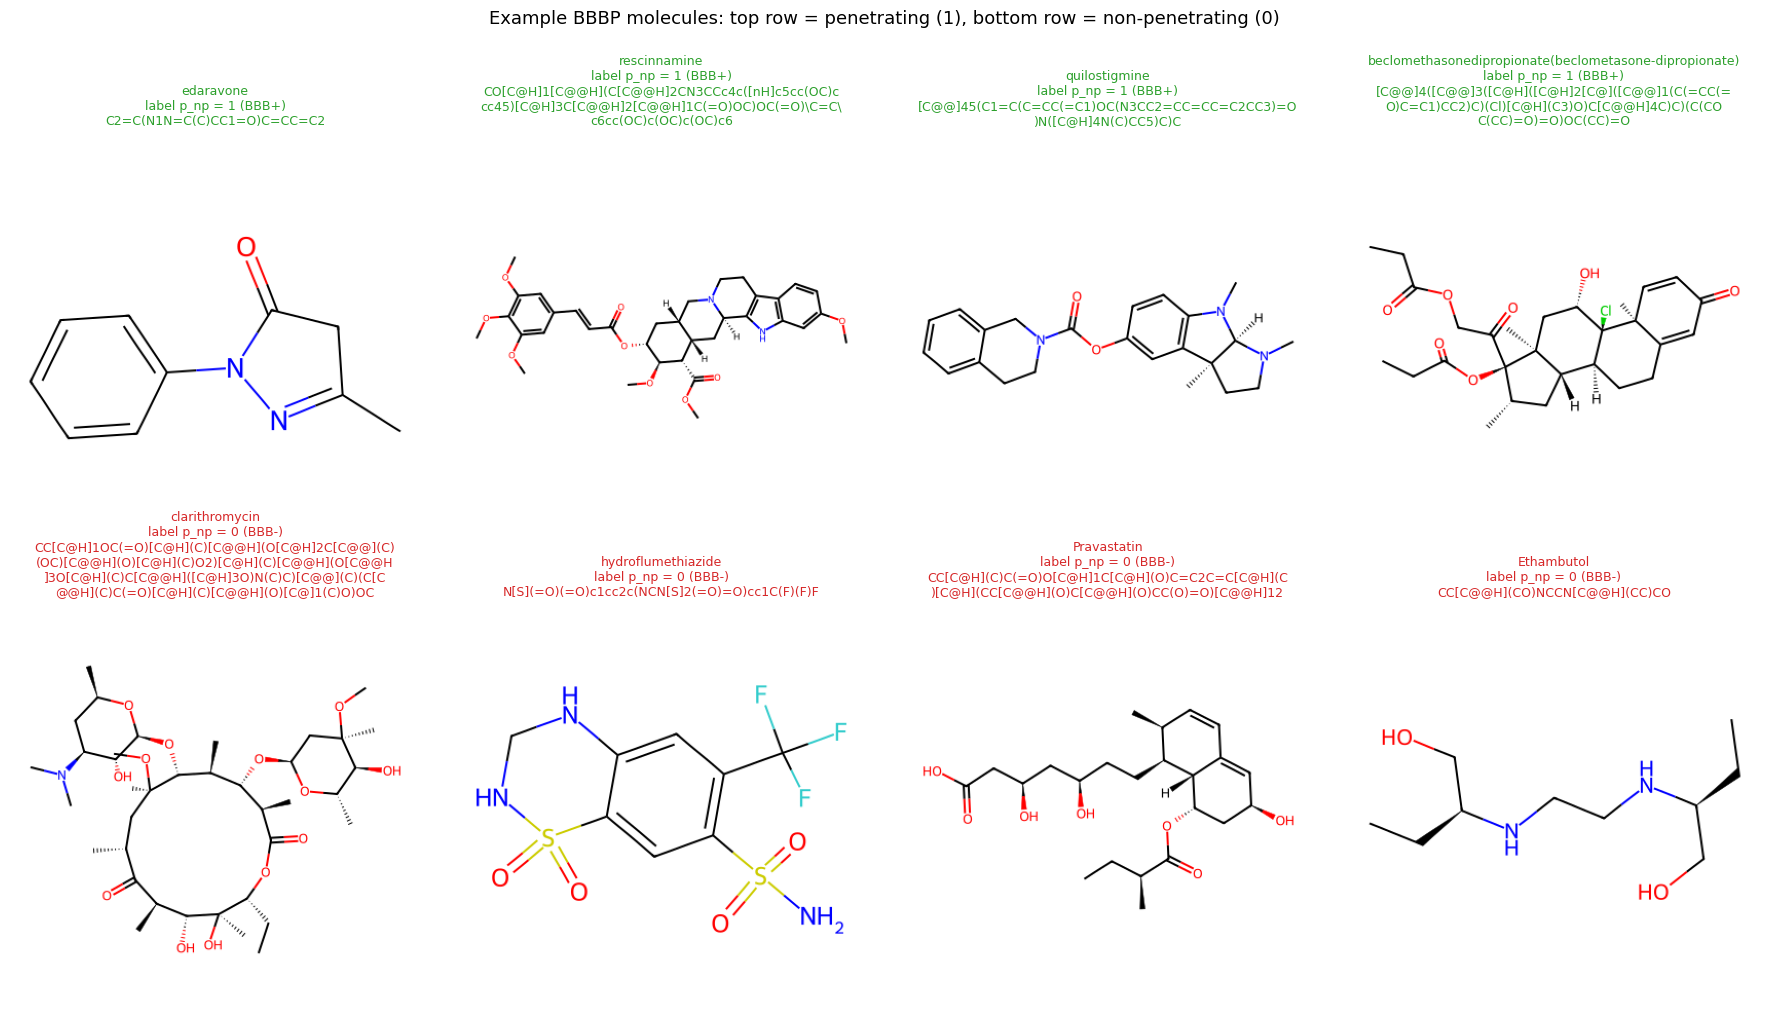

,name,y,smiles
1123,edaravone,1.0,C2=C(N1N=C(C)CC1=O)C=CC=C2
187,rescinnamine,1.0,CO[C@H]1[C@@H](C[C@@H]2CN3CCc4c([nH]c5cc(OC)ccc45)[C@H]3C[C@@H]2[C@@H]1C(=O)OC)OC(=O)\...
1446,quilostigmine,1.0,[C@@]45(C1=C(C=CC(=C1)OC(N3CC2=CC=CC=C2CC3)=O)N([C@H]4N(C)CC5)C)C
1624,beclomethasonedipropionate(beclometasone-dipropionate),1.0,[C@@]4([C@@]3([C@H]([C@H]2[C@]([C@@]1(C(=CC(=O)C=C1)CC2)C)(Cl)[C@H](C3)O)C[C@@H]4C)C)(...
750,clarithromycin,0.0,CC[C@H]1OC(=O)[C@H](C)[C@@H](O[C@H]2C[C@@](C)(OC)[C@@H](O)[C@H](C)O2)[C@H](C)[C@@H](O[...
257,hydroflumethiazide,0.0,N[S](=O)(=O)c1cc2c(NCN[S]2(=O)=O)cc1C(F)(F)F
166,Pravastatin,0.0,CC[C@H](C)C(=O)O[C@H]1C[C@H](O)C=C2C=C[C@H](C)[C@H](CC[C@@H](O)C[C@@H](O)CC(O)=O)[C@@H]12
672,Ethambutol,0.0,CC[C@@H](CO)NCCN[C@@H](CC)CO


In [9]:
rng = np.random.default_rng(SEED)
show_idx = np.concatenate([
    rng.choice(clean_df.index[clean_df["y"] == 1], 4, replace=False),
    rng.choice(clean_df.index[clean_df["y"] == 0], 4, replace=False),
])

fig, axes = plt.subplots(2, 4, figsize=(18, 10))
for ax, i in zip(axes.ravel(), show_idx):
    row = clean_df.loc[i]
    mol = Chem.MolFromSmiles(row["smiles"])
    ax.imshow(Draw.MolToImage(mol, size=(400, 400)))
    ax.axis("off")
    label = int(row["y"])
    ax.set_title(f"{row['name']}\nlabel p_np = {label} ({'BBB+' if label else 'BBB-'})\n"
                 + "\n".join(textwrap.wrap(row["smiles"], 45)),
                 fontsize=9, color="tab:green" if label else "tab:red")
fig.suptitle("Example BBBP molecules: top row = penetrating (1), bottom row = non-penetrating (0)", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

clean_df.loc[show_idx, ["name", "y", "smiles"]]

## A.4 Atom-count and bond-count distributions

Atom count = number of graph nodes (heavy atoms; hydrogens are implicit and stored as the `num_hs` feature).
Bond count = number of chemical bonds = `edge_index.shape[1] / 2`, because each bond is stored as two directed edges.

y              BBB- (0)  BBB+ (1)
n_atoms count    465.00   1500.00
        mean      30.51     22.28
        std       15.06      7.93
        min        8.00      2.00
        25%       22.00     17.00
        50%       28.00     22.00
        75%       35.00     27.00
        max      132.00     76.00
n_bonds count    465.00   1500.00
        mean      32.67     24.10
        std       16.31      9.08
        min        6.00      1.00
        25%       24.00     18.00
        50%       30.00     24.00
        75%       37.00     30.00
        max      145.00     83.00

,count,mean,std,min,25%,50%,75%,max
n_atoms,1965.0,24.22,10.67,2.0,18.0,23.0,29.0,132.0
n_bonds,1965.0,26.13,11.79,1.0,19.0,25.0,31.0,145.0


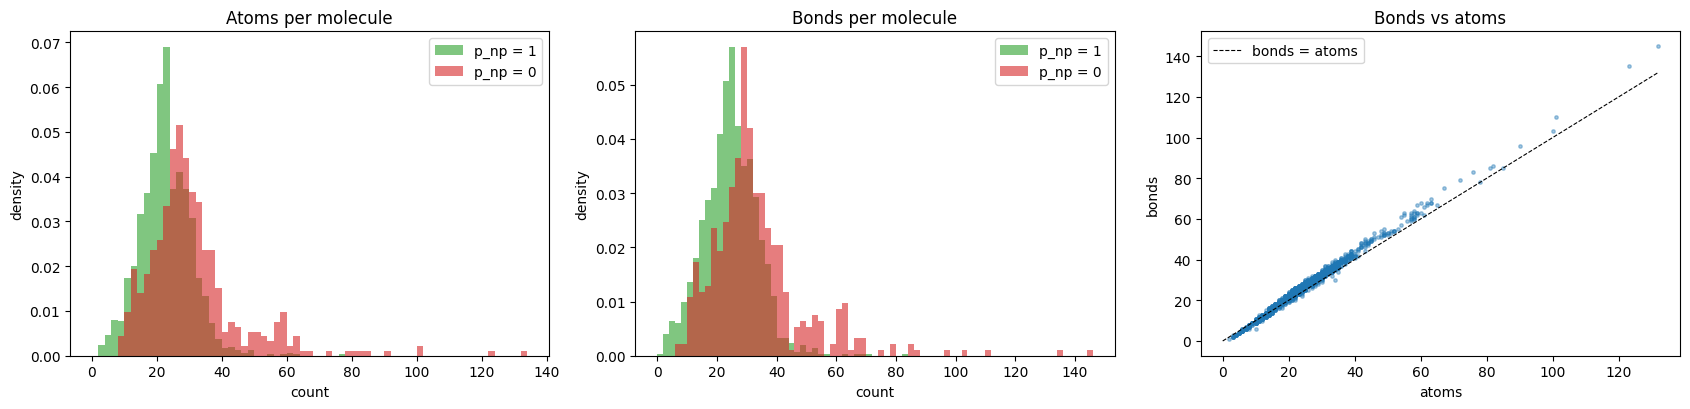

In [10]:
display(clean_df.groupby("y")[["n_atoms", "n_bonds"]].describe().T.round(2)
        .rename(columns={0.0: "BBB- (0)", 1.0: "BBB+ (1)"}))
display(clean_df[["n_atoms", "n_bonds"]].describe().T.round(2))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for ax, col, title in [(axes[0], "n_atoms", "Atoms per molecule"), (axes[1], "n_bonds", "Bonds per molecule")]:
    bins = np.arange(0, clean_df[col].max() + 3, 2)
    for lab, colr in [(1, "tab:green"), (0, "tab:red")]:
        ax.hist(clean_df.loc[clean_df["y"] == lab, col], bins=bins, alpha=0.6, color=colr,
                label=f"p_np = {lab}", density=True)
    ax.set_title(title); ax.set_xlabel("count"); ax.set_ylabel("density"); ax.legend()
axes[2].scatter(clean_df["n_atoms"], clean_df["n_bonds"], s=6, alpha=0.4)
axes[2].plot([0, clean_df["n_atoms"].max()], [0, clean_df["n_atoms"].max()], "k--", lw=0.8, label="bonds = atoms")
axes[2].set_xlabel("atoms"); axes[2].set_ylabel("bonds"); axes[2].set_title("Bonds vs atoms"); axes[2].legend()
plt.tight_layout(); plt.show()

Most molecules are drug-sized (median 23 heavy atoms, long right tail up to >100 atoms for large peptides/macrolides).
Bond count tracks atom count almost linearly (bonds ≈ atoms − 1 + number of rings). BBB− molecules tend to be larger,
which is consistent with the known preference of BBB-penetrating drugs for low molecular weight.

### Inspecting one graph

In [11]:
graph = dataset[0]
print("x.shape          :", tuple(graph.x.shape), "  -> 20 atoms x 9 categorical atom features")
print("edge_index.shape :", tuple(graph.edge_index.shape), "  -> 2 x 40 directed edges = 20 bonds")
print("edge_attr.shape  :", tuple(graph.edge_attr.shape), "  -> 40 directed edges x 3 categorical bond features")
print("y                :", graph.y, " shape", tuple(graph.y.shape), " -> one graph-level label (BBB+)")
print("smiles           :", graph.smiles)
print("\nx (first 5 atoms):\n", graph.x[:5])
print("edge_index (first 8 edges):\n", graph.edge_index[:, :8])

x.shape          : (20, 9)   -> 20 atoms x 9 categorical atom features
edge_index.shape : (2, 40)   -> 2 x 40 directed edges = 20 bonds
edge_attr.shape  : (40, 3)   -> 40 directed edges x 3 categorical bond features
y                : tensor([[1.]])  shape (1, 1)  -> one graph-level label (BBB+)
smiles           : [Cl].CC(C)NCC(O)COc1cccc2ccccc12

x (first 5 atoms):
 tensor([[17,  0,  0,  5,  0,  1,  4,  0,  0],
        [ 6,  0,  4,  5,  3,  0,  4,  0,  0],
        [ 6,  0,  4,  5,  1,  0,  4,  0,  0],
        [ 6,  0,  4,  5,  3,  0,  4,  0,  0],
        [ 7,  0,  3,  5,  1,  0,  4,  0,  0]])
edge_index (first 8 edges):
 tensor([[1, 2, 2, 2, 3, 4, 4, 5],
        [2, 1, 3, 4, 2, 2, 5, 4]])


Note: Propranolol hydrochloride is written as `[Cl].CC(C)NCC(O)...`, so the graph contains a disconnected
chloride node with no edges. That gives 20 nodes (19 heavy atoms of propranolol + 1 Cl). Propranolol is one connected
component with 2 rings (naphthalene), so it has 19 − 1 + 2 = 20 bonds → 40 directed edges. This is also why the
first edge in `edge_index` starts at node 1: node 0 is the isolated chloride.

# Part B — Construct and batch molecular graphs

## B.1 Graph representation and feature encoding

In PyG's `from_smiles` each molecule becomes a `Data` object:

* **Nodes = heavy atoms** (in RDKit atom order). Hydrogens are implicit, stored as a node feature.
* **Edges = chemical bonds.** Each undirected bond *i–j* is stored twice (*i→j* and *j→i*) in `edge_index` (shape `[2, 2·n_bonds]`)
  so messages can flow both ways. `edge_attr[k]` describes the bond of edge *k*.
* `x` (shape `[n_atoms, 9]`) and `edge_attr` (shape `[2·n_bonds, 3]`) contain **integer category codes**: each value is an
  *index into a vocabulary list* (`torch_geometric.utils.smiles.x_map` / `e_map`), not the physical value itself.
  For example formal charge 0 is stored as code 5, because the vocabulary is `[-5, …, 6]`.

In [12]:
atom_desc = {
    "atomic_num": "element (atomic number Z), e.g. code 6 = carbon",
    "chirality": "tetrahedral chirality tag (R/S information in CW/CCW form)",
    "degree": "total number of bonded neighbours including implicit H",
    "formal_charge": "formal charge of the atom",
    "num_hs": "total number of attached hydrogens",
    "num_radical_electrons": "number of unpaired electrons",
    "hybridization": "orbital hybridization (SP, SP2, SP3, ...)",
    "is_aromatic": "atom is part of an aromatic system",
    "is_in_ring": "atom is part of any ring",
}
bond_desc = {
    "bond_type": "bond order: SINGLE, DOUBLE, TRIPLE, AROMATIC, ...",
    "stereo": "double-bond stereochemistry (E/Z, cis/trans, none)",
    "is_conjugated": "bond is part of a conjugated system",
}
all_x  = torch.cat([g.x for g in dataset])
all_ea = torch.cat([g.edge_attr for g in dataset if g.edge_attr.numel()])

def feature_table(fmap, desc, data):
    rows = []
    for col, (name, vocab) in enumerate(fmap.items()):
        used = sorted(data[:, col].unique().tolist())
        rows.append({"column": col, "feature": name, "meaning": desc[name],
                     "vocab_size": len(vocab), "categories seen in BBBP": [vocab[u] for u in used]})
    return pd.DataFrame(rows)

print("Atom (node) features, graph.x columns:")
display(feature_table(x_map, atom_desc, all_x))
print("Bond (edge) features, graph.edge_attr columns:")
display(feature_table(e_map, bond_desc, all_ea))

Atom (node) features, graph.x columns:


,column,feature,meaning,vocab_size,categories seen in BBBP
0,0,atomic_num,"element (atomic number Z), e.g. code 6 = carbon",119,"[1, 5, 6, 7, 8, 9, 11, 15, 16, 17, 20, 35, 53]"
1,1,chirality,tetrahedral chirality tag (R/S information in CW/CCW form),9,"[CHI_UNSPECIFIED, CHI_TETRAHEDRAL_CW, CHI_TETRAHEDRAL_CCW]"
2,2,degree,total number of bonded neighbours including implicit H,11,"[0, 1, 2, 3, 4]"
3,3,formal_charge,formal charge of the atom,12,"[-1, 0, 1, 2]"
4,4,num_hs,total number of attached hydrogens,9,"[0, 1, 2, 3]"
5,5,num_radical_electrons,number of unpaired electrons,5,"[0, 1]"
6,6,hybridization,"orbital hybridization (SP, SP2, SP3, ...)",8,"[S, SP, SP2, SP3]"
7,7,is_aromatic,atom is part of an aromatic system,2,"[False, True]"
8,8,is_in_ring,atom is part of any ring,2,"[False, True]"


Bond (edge) features, graph.edge_attr columns:


,column,feature,meaning,vocab_size,categories seen in BBBP
0,0,bond_type,"bond order: SINGLE, DOUBLE, TRIPLE, AROMATIC, ...",22,"[SINGLE, DOUBLE, TRIPLE, AROMATIC]"
1,1,stereo,"double-bond stereochemistry (E/Z, cis/trans, none)",6,"[STEREONONE, STEREOZ, STEREOE]"
2,2,is_conjugated,bond is part of a conjugated system,2,"[False, True]"


**Encoding choice: one-hot encoding.** Every categorical column is replaced by a one-hot block whose length equals the
full PyG vocabulary size, and the blocks are concatenated:

* atoms: 119 + 9 + 11 + 12 + 9 + 5 + 8 + 2 + 2 = **177-dimensional** binary node vector
* bonds: 22 + 6 + 2 = **30-dimensional** binary edge vector

So no ordering or distance between codes is implied (carbon = 6 is not "half of" sulfur = 16), which is what would
happen if the raw integer codes were fed as continuous numbers. Using the fixed full vocabulary (not only the categories
seen in the data) keeps the encoding identical for every split and for any unseen molecule. The GNN's first linear layer
on top of these one-hot vectors is equivalent to a trainable embedding per category, summed over columns.

The raw codes are kept as `x_cat` / `edge_attr_cat` for plotting and inspection only.

In [13]:
ATOM_VOCAB = [len(v) for v in x_map.values()]
BOND_VOCAB = [len(v) for v in e_map.values()]
ATOM_DIM, BOND_DIM = sum(ATOM_VOCAB), sum(BOND_VOCAB)

def one_hot_columns(codes: torch.Tensor, vocab_sizes) -> torch.Tensor:
    """codes: [N, C] long tensor of category indices -> [N, sum(vocab_sizes)] float one-hot."""
    if codes.numel() == 0:
        return torch.zeros((codes.size(0), sum(vocab_sizes)), dtype=torch.float)
    blocks = [torch.nn.functional.one_hot(codes[:, c], num_classes=k) for c, k in enumerate(vocab_sizes)]
    return torch.cat(blocks, dim=1).float()

def encode_graph(g, canonical, name):
    d = g.clone()
    d.x_cat, d.edge_attr_cat = g.x, g.edge_attr.view(-1, len(BOND_VOCAB))
    d.x = one_hot_columns(g.x, ATOM_VOCAB)
    d.edge_attr = one_hot_columns(d.edge_attr_cat, BOND_VOCAB)
    d.y = g.y.view(1, 1).float()          # one label per graph -> batch.y has shape [num_graphs, 1]
    d.canonical = canonical
    d.name = name
    return d

clean_graphs = [encode_graph(dataset[int(r.idx)], r.canonical, r.name) for r in clean_df.itertuples()]
g0 = clean_graphs[0]
print(f"Cleaned & encoded graphs: {len(clean_graphs)}")
print(f"Atom one-hot dim = {ATOM_DIM}, bond one-hot dim = {BOND_DIM}")
print(g0)
# each atom row must contain exactly one '1' per categorical column
assert torch.all(g0.x.sum(1) == len(ATOM_VOCAB)) and torch.all(g0.edge_attr.sum(1) == len(BOND_VOCAB))
print("Row sums of one-hot x (should all equal 9):", g0.x.sum(1)[:10].tolist())

Cleaned & encoded graphs: 1965
Atom one-hot dim = 177, bond one-hot dim = 30
Data(x=[20, 177], edge_index=[2, 40], edge_attr=[40, 30], smiles='[Cl].CC(C)NCC(O)COc1cccc2ccccc12', y=[1, 1], x_cat=[20, 9], edge_attr_cat=[40, 3], canonical='CC(C)NCC(O)COc1cccc2ccccc12.[Cl]', name='Propanolol')
Row sums of one-hot x (should all equal 9): [9.0, 9.0, 9.0, 9.0, 9.0, 9.0, 9.0, 9.0, 9.0, 9.0]


## B.2 The same molecule as a chemical structure and as a node–edge graph

I use **paracetamol** (acetaminophen, `CC(=O)Nc1ccc(O)cc1`, BBB+): it is small enough to read and still contains
an aromatic ring, a C=O double bond and heteroatoms.

Name: acetaminophen | label: 1 | SMILES: CC(=O)Nc1ccc(O)cc1
x.shape (11, 177) | edge_index.shape (2, 22) | edge_attr.shape (22, 30)


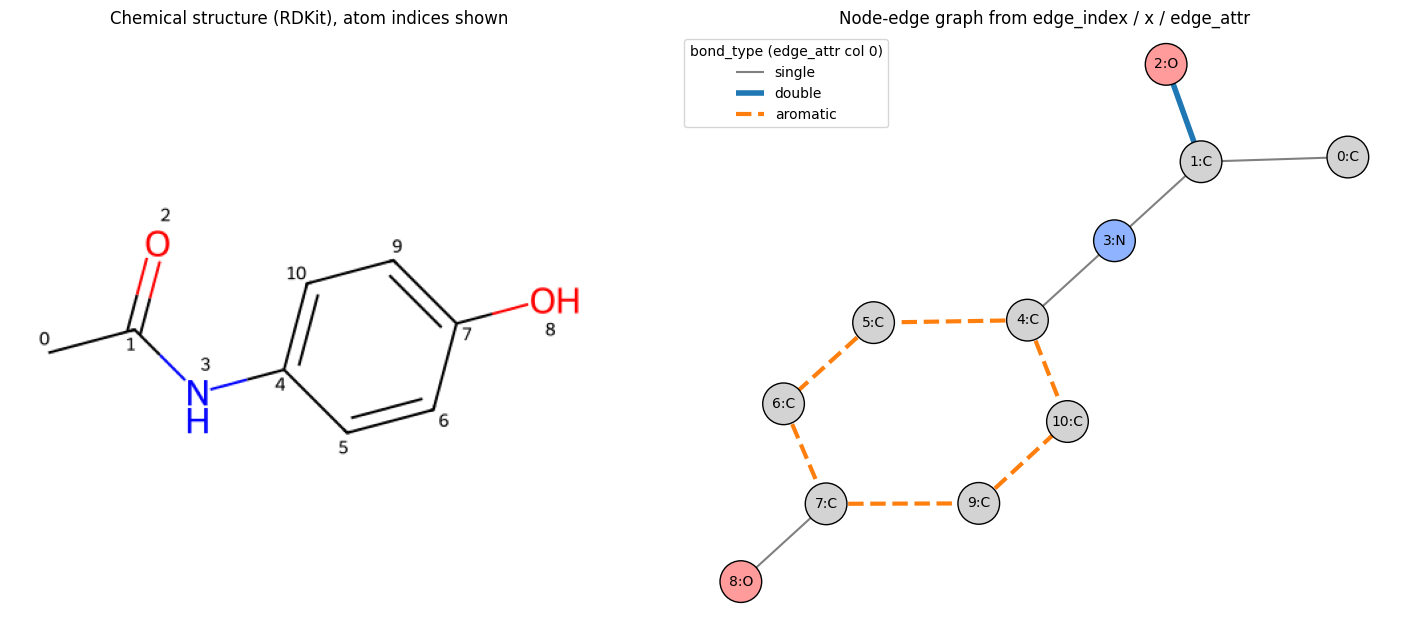

Node table (decoded x_cat, one row per node):


,symbol,atomic_num,degree,num_hs,hybridization,is_aromatic,is_in_ring,formal_charge
0,C,6,4,3,SP3,False,False,0
1,C,6,3,0,SP2,False,False,0
2,O,8,1,0,SP2,False,False,0
3,N,7,3,1,SP2,False,False,0
4,C,6,3,0,SP2,True,True,0
5,C,6,3,1,SP2,True,True,0
6,C,6,3,1,SP2,True,True,0
7,C,6,3,0,SP2,True,True,0
8,O,8,2,1,SP2,False,False,0
9,C,6,3,1,SP2,True,True,0


Edge table (both directions of every bond):


,edge k,src,dst,bond_type,stereo,is_conjugated
0,0,0:C,1:C,SINGLE,STEREONONE,False
1,1,1:C,0:C,SINGLE,STEREONONE,False
2,2,1:C,2:O,DOUBLE,STEREONONE,True
3,3,1:C,3:N,SINGLE,STEREONONE,True
4,4,2:O,1:C,DOUBLE,STEREONONE,True
5,5,3:N,1:C,SINGLE,STEREONONE,True
6,6,3:N,4:C,SINGLE,STEREONONE,True
7,7,4:C,3:N,SINGLE,STEREONONE,True


In [14]:
ex_pos = int(np.flatnonzero(clean_df["canonical"] == Chem.MolToSmiles(Chem.MolFromSmiles("CC(=O)Nc1ccc(O)cc1")))[0])
ex = clean_graphs[ex_pos]
mol = Chem.MolFromSmiles(ex.smiles)          # same parsing as PyG -> same atom order / indices
print("Name:", ex.name, "| label:", int(ex.y.item()), "| SMILES:", ex.smiles)
print("x.shape", tuple(ex.x.shape), "| edge_index.shape", tuple(ex.edge_index.shape), "| edge_attr.shape", tuple(ex.edge_attr.shape))

# --- left: conventional chemical structure with RDKit atom indices
d_opts_mol = Chem.Mol(mol)
for a in d_opts_mol.GetAtoms():
    a.SetProp("atomNote", str(a.GetIdx()))
struct_img = Draw.MolToImage(d_opts_mol, size=(450, 450))

# --- right: node-edge graph built ONLY from the PyG tensors
sym = [Chem.GetPeriodicTable().GetElementSymbol(x_map["atomic_num"][int(c)]) for c in ex.x_cat[:, 0]]
bond_names = e_map["bond_type"]
G = nx.Graph()
for i in range(ex.num_nodes):
    G.add_node(i, label=f"{i}:{sym[i]}")
for k in range(ex.edge_index.size(1)):
    i, j = ex.edge_index[:, k].tolist()
    if i < j:                                # draw each undirected bond once
        G.add_edge(i, j, btype=bond_names[int(ex.edge_attr_cat[k, 0])])

style = {"SINGLE": ("grey", 1.5, "solid"), "DOUBLE": ("tab:blue", 4, "solid"), "AROMATIC": ("tab:orange", 3, "dashed")}
pos = nx.kamada_kawai_layout(G)
elem_color = {"C": "lightgrey", "N": "#8fb3ff", "O": "#ff9b9b"}

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
axes[0].imshow(struct_img); axes[0].axis("off"); axes[0].set_title("Chemical structure (RDKit), atom indices shown")
for bt, (c, w, ls) in style.items():
    es = [(u, v) for u, v, d in G.edges(data=True) if d["btype"] == bt]
    nx.draw_networkx_edges(G, pos, edgelist=es, edge_color=c, width=w, style=ls, ax=axes[1], label=bt.lower())
nx.draw_networkx_nodes(G, pos, node_color=[elem_color.get(s, "khaki") for s in sym], node_size=900, edgecolors="k", ax=axes[1])
nx.draw_networkx_labels(G, pos, labels=nx.get_node_attributes(G, "label"), font_size=10, ax=axes[1])
axes[1].legend(title="bond_type (edge_attr col 0)", loc="upper left")
axes[1].set_title("Node-edge graph from edge_index / x / edge_attr"); axes[1].axis("off")
plt.tight_layout(); plt.show()

atom_tbl = pd.DataFrame(ex.x_cat.numpy(), columns=list(x_map.keys()))
atom_tbl.insert(0, "symbol", sym)
for col, vocab in x_map.items():                         # decode codes -> human-readable categories
    atom_tbl[col] = [vocab[int(c)] for c in atom_tbl[col]]
print("Node table (decoded x_cat, one row per node):")
display(atom_tbl[["symbol", "atomic_num", "degree", "num_hs", "hybridization", "is_aromatic", "is_in_ring", "formal_charge"]])

bond_rows = []
for k in range(ex.edge_index.size(1)):
    i, j = ex.edge_index[:, k].tolist()
    bond_rows.append({"edge k": k, "src": f"{i}:{sym[i]}", "dst": f"{j}:{sym[j]}",
                      **{c: v[int(ex.edge_attr_cat[k, n])] for n, (c, v) in enumerate(e_map.items())}})
print("Edge table (both directions of every bond):")
display(pd.DataFrame(bond_rows).head(8))

**Correspondence between the two views.**

* Each **atom** in the drawing (label = RDKit atom index) is exactly one **node** with the same index in the graph
  (row *i* of `x`). Hydrogens are not nodes: the N–H and O–H hydrogens appear only as `num_hs = 1` on nodes 3 and 8.
* Each **bond** in the drawing is one **undirected edge** in the graph, stored twice in `edge_index` (e.g. `(1,2)` and
  `(2,1)`), so 11 bonds → 22 directed edges. The C=O bond (1–2) is the only `DOUBLE` edge; the six ring bonds
  (4–5–6–7–9–10–4) are `AROMATIC` (shown dashed) and those atoms have `is_aromatic = True` and `is_in_ring = True`.
* The graph drops 2-D coordinates and drawing conventions. It keeps only *which* atoms are connected and the
  categorical atom/bond features, which is all the GNN sees.

## B.3 PyG DataLoader and batch shapes

In [15]:
loader = DataLoader(clean_graphs, batch_size=32, shuffle=True, generator=torch.Generator().manual_seed(SEED))
batch = next(iter(loader))
print(batch)
print(f"num_graphs        : {batch.num_graphs}")
print(f"x.shape           : {tuple(batch.x.shape)}   = (total atoms in the 32 molecules, {ATOM_DIM} one-hot atom features)")
print(f"edge_index.shape  : {tuple(batch.edge_index.shape)}   = (2, total directed edges); node ids are offset per graph")
print(f"edge_attr.shape   : {tuple(batch.edge_attr.shape)}   = (total directed edges, {BOND_DIM} one-hot bond features)")
print(f"batch.shape       : {tuple(batch.batch.shape)}   = one graph id (0..31) per atom")
print(f"y.shape           : {tuple(batch.y.shape)}   = one label per molecule")
print(f"ptr (first 6)     : {batch.ptr[:6].tolist()}  -> node offset of each graph")
print("atoms per graph   :", torch.bincount(batch.batch).tolist())

DataBatch(x=[776, 177], edge_index=[2, 1690], edge_attr=[1690, 30], smiles=[32], y=[32, 1], x_cat=[776, 9], edge_attr_cat=[1690, 3], canonical=[32], name=[32], batch=[776], ptr=[33])
num_graphs        : 32
x.shape           : (776, 177)   = (total atoms in the 32 molecules, 177 one-hot atom features)
edge_index.shape  : (2, 1690)   = (2, total directed edges); node ids are offset per graph
edge_attr.shape   : (1690, 30)   = (total directed edges, 30 one-hot bond features)
batch.shape       : (776,)   = one graph id (0..31) per atom
y.shape           : (32, 1)   = one label per molecule
ptr (first 6)     : [0, 20, 62, 81, 103, 125]  -> node offset of each graph
atoms per graph   : [20, 42, 19, 22, 22, 17, 22, 28, 39, 14, 16, 28, 53, 16, 29, 21, 27, 14, 19, 31, 42, 26, 6, 22, 13, 24, 21, 15, 4, 26, 20, 58]


PyG batches graphs by putting them side by side as **one large disconnected graph**, with no padding:

* `x` stacks the node features of all molecules: `[Σ atoms, 177]`.
* `edge_index` stacks the edges, and each graph's node indices are **shifted by the number of atoms before it**
  (`ptr`), so edges never connect two different molecules: `[2, Σ directed edges]`.
* `edge_attr` is aligned with `edge_index` column-for-column: `[Σ directed edges, 30]`.
* `batch` is the node→graph assignment vector `[Σ atoms]`. Graph-level pooling (e.g. `global_mean_pool(h, batch)`)
  uses it to collapse node embeddings into one vector per molecule.
* `y` is `[32, 1]`: one BBBP label per **graph**, not per atom.

## B.4 Integrity checks

In [16]:
def check_graphs(graphs):
    for g in graphs:
        assert g.y.numel() == 1 and torch.isfinite(g.y).all(), f"non-finite / missing label: {g.smiles}"
        assert g.num_nodes >= 1 and g.x.size(0) >= 1,          f"empty graph: {g.smiles}"
        if g.edge_index.numel():
            assert int(g.edge_index.max()) < g.num_nodes,      f"edge points outside graph: {g.smiles}"
        assert g.edge_attr.size(0) == g.edge_index.size(1),   f"edge_attr/edge_index mismatch: {g.smiles}"
        assert g.x.size(1) == ATOM_DIM and g.edge_attr.size(1) == BOND_DIM
    print(f"[OK] {len(graphs)} graphs: all labels finite, every graph has >=1 atom, edges consistent")

def check_loader(graphs, batch_size=64):
    dl = DataLoader(graphs, batch_size=batch_size, shuffle=False)
    seen_smiles, n_graphs, n_nodes = [], 0, 0
    for b in dl:
        assert b.y.size(0) == b.num_graphs,                     "labels != number of graphs in batch"
        assert int(b.batch.max()) + 1 == b.num_graphs,          "batch vector does not cover all graphs"
        assert torch.isfinite(b.y).all()
        assert torch.all(torch.bincount(b.batch, minlength=b.num_graphs) >= 1), "graph without atoms in batch"
        n_graphs += b.num_graphs
        n_nodes  += b.num_nodes
        seen_smiles += list(b.canonical)
    assert n_graphs == len(graphs),                               f"lost graphs: {n_graphs} vs {len(graphs)}"
    assert n_nodes == sum(g.num_nodes for g in graphs),           "lost atoms during batching"
    assert seen_smiles == [g.canonical for g in graphs],          "molecule order / identity changed"
    assert len(set(seen_smiles)) == len(graphs),                  "duplicate molecule after cleaning"
    print(f"[OK] {len(dl)} batches: batch.y matches num_graphs; {n_graphs}/{len(graphs)} molecules and "
          f"{n_nodes} atoms recovered, identical order, no duplicates")

check_graphs(clean_graphs)
check_loader(clean_graphs)
assert len(clean_graphs) == len(clean_df)

[OK] 1965 graphs: all labels finite, every graph has >=1 atom, edges consistent
[OK] 31 batches: batch.y matches num_graphs; 1965/1965 molecules and 47599 atoms recovered, identical order, no duplicates
